# TP 3 - Pipeline LLM
**Cours NLP et Transformers — CY Tech**

---

## 0. Environnement

In [3]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

In [4]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

In [ ]:
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

## 3. Construire le jeu de données étiqueté

In [5]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte)."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

--- 20 locuteurs les plus fréquents ---
locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
KING RICHARD II       98
WARWICK               98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64

--- Longueur des répliques (mots) ---
count    7094.0
mean       27.2
std        39.1
min         1.0
25%         7.0
50%        14.0
75%        32.0
max       578.0
Name: n_mots, dtype: float64


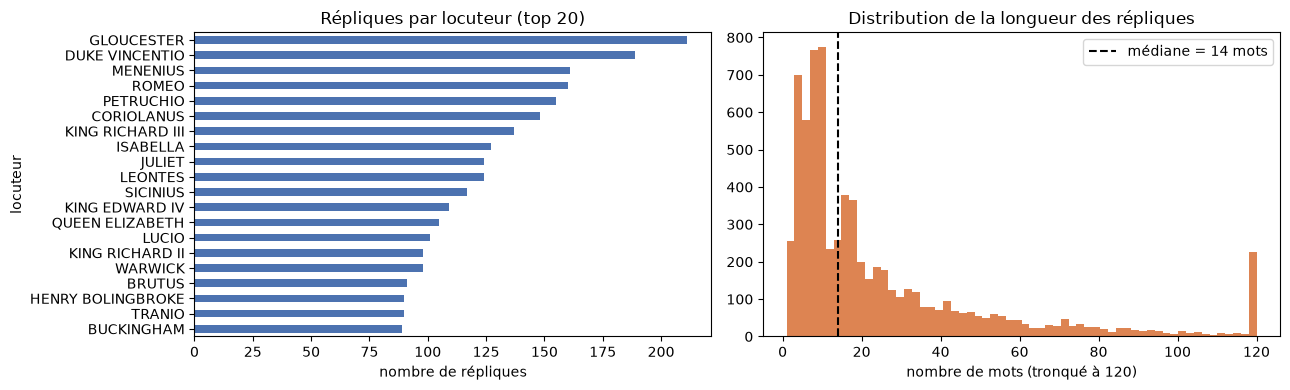

In [6]:
top20 = df["locuteur"].value_counts().head(20)
print("--- 20 locuteurs les plus fréquents ---")
print(top20)

df["n_mots"] = df["replique"].str.split().str.len()

print("\n--- Longueur des répliques (mots) ---")
print(df["n_mots"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

top20.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set_title("Répliques par locuteur (top 20)")
axes[0].set_xlabel("nombre de répliques")

axes[1].hist(df["n_mots"].clip(upper=120), bins=60, color="#DD8452")
axes[1].axvline(df["n_mots"].median(), color="black", ls="--",
                label=f"médiane = {df['n_mots'].median():.0f} mots")
axes[1].set_title("Distribution de la longueur des répliques")
axes[1].set_xlabel("nombre de mots (tronqué à 120)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Définir la tâche

### ✅ Choix retenu dans ce corrigé

| Décision | Valeur | Justification |
|---|---|---|
| Nombre de locuteurs | **5** | effectifs comparables (126 à 196), problème lisible, matrice de confusion 5×5 interprétable à l'œil |
| Seuil de longueur | **≥ 5 mots** | une réplique de type « Ay, my lord » ne porte aucun signal identifiant ; on retire du bruit pur |
| Volume final | ~761 exemples | faible, mais suffisant pour un modèle linéaire creux |

**Autres choix acceptables :** 10 locuteurs (problème plus difficile, permet de montrer la
chute du F1 macro), seuil à 10 mots (moins d'exemples mais moins de bruit), pas de seuil du
tout à condition que l'étudiant en discute l'effet.

**Ce qui n'est pas acceptable :** garder les 297 locuteurs sans justification, ou choisir un
seuil sans jamais mesurer combien d'exemples il élimine.

In [7]:
N_LOCUTEURS = 5
MIN_MOTS = 5

top_locuteurs = df["locuteur"].value_counts().head(N_LOCUTEURS).index.tolist()

donnees = (
    df[df["locuteur"].isin(top_locuteurs)]
      .query("n_mots >= @MIN_MOTS")
      .loc[:, ["replique", "locuteur"]]
      .reset_index(drop=True)
)

print("Répartition des classes :")
print(donnees["locuteur"].value_counts())

ratio = donnees["locuteur"].value_counts()
print(f"\n{len(donnees)} exemples retenus")
print(f"Ratio classe majoritaire / minoritaire : {ratio.max() / ratio.min():.2f}")
print(f"Part de la classe majoritaire : {ratio.max() / len(donnees):.1%}  <-- plancher de l'accuracy")

Répartition des classes :
locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64

761 exemples retenus
Ratio classe majoritaire / minoritaire : 1.56
Part de la classe majoritaire : 25.8%  <-- plancher de l'accuracy


## 5. ⚠️ Découper AVANT toute transformation

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"],
    donnees["locuteur"],
    test_size=0.20,
    stratify=donnees["locuteur"],   # indispensable : classes déséquilibrées
    random_state=RANDOM_STATE,
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

print("\nProportions par classe (vérification de la stratification) :")
comparaison = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)
print(comparaison)

train : 608 exemples
test  : 153 exemples

Proportions par classe (vérification de la stratification) :
                train   test
locuteur                    
GLOUCESTER      0.257  0.261
DUKE VINCENTIO  0.217  0.216
ROMEO           0.186  0.183
PETRUCHIO       0.174  0.176
MENENIUS        0.166  0.163


## 6. Représenter le texte

### ✅ Choix retenus et justification

| Paramètre | Valeur | Pourquoi |
|---|---|---|
| `lowercase` | `True` | la casse ne distingue pas les locuteurs ici ; en analyse de sentiment ce serait discutable (« ÉNORME » porte de l'émotion) |
| `ngram_range` | `(1, 2)` | les bigrammes récupèrent un peu d'ordre local (« my lord », « good my ») ; gain modeste mais réel |
| `min_df` | `2` | un terme vu une seule fois ne peut pas généraliser, il ne fait que grossir le vocabulaire |
| `max_df` | `0.8` | écarte les termes présents dans plus de 80 % des documents |
| `stop_words` | **`None`** | ⚠️ **volontairement désactivé** — voir la remarque ci-dessous |
| `sublinear_tf` | `True` | remplace tf par 1 + log(tf) : 10 occurrences ne valent pas 10 fois 1 |

> **⚠️ Le piège des stopwords, ici.** La tentation est de mettre `stop_words='english'`.
> C'est une mauvaise idée pour cette tâche : les mots grammaticaux (`thou`, `thy`, `my`,
> `sir`) font partie du **registre de langue** d'un personnage et portent donc du signal
> identifiant. Les supprimer dégrade le score.
>
> C'est le même mécanisme que le « Je n'ai **pas** aimé ce film » du cours : un stopword
> n'est un mot vide que **relativement à une tâche**.

In [9]:
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.8,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)   # fit + transform  -> TRAIN uniquement
Xte = vectoriseur.transform(X_test)        # transform seul   -> TEST

densite = Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1])

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Matrice test  : {Xte.shape}")
print(f"Valeurs non nulles : {densite:.4%}")
print(f"Soit {1 - densite:.2%} de zéros")

dense_mo = Xtr.shape[0] * Xtr.shape[1] * 8 / 1e6
creux_mo = (Xtr.data.nbytes + Xtr.indices.nbytes + Xtr.indptr.nbytes) / 1e6
print(f"\nStockage dense : {dense_mo:.1f} Mo")
print(f"Stockage creux : {creux_mo:.2f} Mo  ({dense_mo / creux_mo:.0f}x moins)")

Taille du vocabulaire : 3,464
Matrice train : (608, 3464)
Matrice test  : (153, 3464)
Valeurs non nulles : 0.9716%
Soit 99.03% de zéros

Stockage dense : 16.8 Mo
Stockage creux : 0.25 Mo  (68x moins)


## 7. Modéliser

### 7.1 La baseline — d'abord, sans exception

In [47]:
baselines = {
    "Dummy (classe majoritaire)": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Dummy (aléatoire stratifié)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

resultats_baselines = []

for nom, modele in baselines.items():
    modele.fit(Xtr, y_train)
    pred = modele.predict(Xte)
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")

    resultats_baselines.append({
        "modèle": nom,
        "accuracy": acc,
        "F1 macro": f1
    })

    print(
        f"{nom:<30} "
        f"accuracy = {acc:.3f}   "
        f"F1 macro = {f1:.3f}"
    )

baseline_df = pd.DataFrame(resultats_baselines)

Dummy (classe majoritaire)     accuracy = 0.261   F1 macro = 0.083
Dummy (aléatoire stratifié)    accuracy = 0.196   F1 macro = 0.189


> **✅ Le score de la baseline : 0,261 en accuracy, 0,083 en F1 macro.**
>
> L'écart entre les deux chiffres est instructif et vaut d'être commenté : la stratégie
> « classe majoritaire » obtient 26 % d'accuracy en ne prédisant **qu'une seule classe**.
> Son F1 macro s'effondre à 0,08 parce que quatre classes sur cinq ont un rappel nul.
>
> C'est la démonstration en miniature du message de la slide 19 : **l'accuracy peut
> paraître honorable pour un modèle qui ne fait strictement rien.**

### 7.2 Modèle LLM local

On reprend exactement la même tâche d'identifier, parmi les 5 locuteurs les
plus fréquents, qui prononce une réplique, mais cette fois en utilisant un modèle LLM local (via Ollama).

Note: API REST de Ollama -> port 11434.

> **Prérequis local** : avoir [Ollama](https://ollama.com) installé et lancé (`ollama serve`),
> et un modèle téléchargé (ex. `ollama pull llama3.2`).

#### Connexion à ollama

In [11]:
import ollama

# Liste des modèles
models = ollama.list()
for model in models["models"]:
    print(model["model"])

MODELE_LLM = "gemma3:4b"

gemma3:4b


#### Prompting

In [14]:
def prompt_zero_shot(replique: str, top_locuteurs: list) -> str:
    candidats = ", ".join(top_locuteurs)
    return (
        "Tu es un expert des pièces de Shakespeare. "
        f"Voici une réplique extraite d'une pièce. Identifie qui, parmi ces {len(top_locuteurs)} "
        f"personnages, prononce cette réplique : {candidats}.\n\n"
        f"Réplique : « {replique} »\n\n"
        "Réponds uniquement par le nom du personnage, exactement comme il apparaît dans la liste, "
        "sans phrase, sans ponctuation, sans explication."
    )


def examples_few_shot(top_locuteurs: list, n_par_classe: int = 1) -> str:
    """
        Pioche n_par_classe exemples par locuteur dans X_train (jamais dans le test) pour le few-shot.
    """

    train_df = pd.DataFrame({"replique": X_train.values, "locuteur": y_train.values})
    blocs = []
    for loc in top_locuteurs:
        sub = train_df[train_df["locuteur"] == loc].sample(n=n_par_classe, random_state=RANDOM_STATE)
        for _, row in sub.iterrows():
            blocs.append(f"Réplique : « {row['replique']} »\nPersonnage : {loc}")
    return "\n\n".join(blocs)


def prompt_few_shot(replique: str, top_locuteurs: list) -> str:
    candidats = ", ".join(top_locuteurs)
    expl = examples_few_shot(top_locuteurs,1)

    return (
        "Tu es un expert des pièces de Shakespeare. "
        f"Voici des exemples de répliques déjà attribuées à leur personnage, parmi cette liste : {candidats}.\n\n"
        f"{expl}\n\n"
        f"Nouvelle réplique : « {replique} »\n\n"
        "Réponds uniquement par le nom du personnage le plus probable, exactement comme il apparaît "
        "dans la liste ci-dessus, sans phrase, sans ponctuation, sans explication."
    )


print("--- Exemple de prompt zero-shot ---\n")
print(prompt_few_shot(X_test.iloc[0], top_locuteurs))


--- Exemple de prompt zero-shot ---

Tu es un expert des pièces de Shakespeare. Voici des exemples de répliques déjà attribuées à leur personnage, parmi cette liste : GLOUCESTER, DUKE VINCENTIO, MENENIUS, ROMEO, PETRUCHIO.

Réplique : « I cannot blame her: by God's holy mother, She hath had too much wrong; and I repent My part thereof that I have done to her. »
Personnage : GLOUCESTER

Réplique : « Respect to your great place! and let the devil Be sometime honour'd for his burning throne! Where is the duke? 'tis he should hear me speak. »
Personnage : DUKE VINCENTIO

Réplique : « Sir, I shall tell you. With a kind of smile, Which ne'er came from the lungs, but even thus-- For, look you, I may make the belly smile As well as speak--it tauntingly replied To the discontented members, the mutinous parts That envied his receipt; even so most fitly As you malign our senators for that They are not such as you. »
Personnage : MENENIUS

Réplique : « As if that name, Shot from the deadly level o

#### Passage au LLM

In [15]:
def model_call(prompt: str, model: str, temperature: float = 0.0) -> str:
    try:
        response = ollama.generate(
            model=model,
            prompt=prompt,
            options={"temperature": temperature},
        )
        return response["response"].strip()
    except ollama.ResponseError as e:
        raise RuntimeError(f"Erreur Ollama : {e}") from e



# Nombre de répliques à envoyer au LLM pour qu'il fasse des prédictions
N_ECHANTILLON_LLM = 60  # limité pour un temps d'exécution raisonnable; mettre len(X_test) pour tout évaluer

echantillon = (
    pd.DataFrame({"replique": X_test.values, "vrai": y_test.values})
    .sample(n=min(N_ECHANTILLON_LLM, len(X_test)), random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(f"{len(echantillon)} répliques seront envoyées au LLM (sur {len(X_test)} au total dans le test).")

60 répliques seront envoyées au LLM (sur 153 au total dans le test).


In [26]:
def llm_pipeline(echantillon: pd.DataFrame, prompt_methode,strategie: str, top_locuteurs:list, model:str) -> pd.DataFrame:
    raw_out = []
    for i, replique in enumerate(echantillon["replique"]):
        prompt = prompt_methode(replique, top_locuteurs)
        out = model_call(prompt, model)
        raw_out.append(out)

        # Voir la progression du traitement
        if (i + 1) % 10 == 0:
            print(f"  [{strategie}] {i + 1}/{len(echantillon)} traitées")
            
    res = echantillon.copy()
    res["raw_out"] = raw_out
    res["strategie"] = strategie
    return res

resultats_zero_shot = llm_pipeline(echantillon, prompt_zero_shot, "zero-shot", top_locuteurs, MODELE_LLM)
resultats_few_shot = llm_pipeline(echantillon, prompt_few_shot, "few-shot", top_locuteurs, MODELE_LLM)

  [zero-shot] 10/60 traitées
  [zero-shot] 20/60 traitées
  [zero-shot] 30/60 traitées
  [zero-shot] 40/60 traitées
  [zero-shot] 50/60 traitées
  [zero-shot] 60/60 traitées
  [few-shot] 10/60 traitées
  [few-shot] 20/60 traitées
  [few-shot] 30/60 traitées
  [few-shot] 40/60 traitées
  [few-shot] 50/60 traitées
  [few-shot] 60/60 traitées


In [31]:
def extraire_locuteur(raw_out: str, candidats:list) -> str:
    """Fait correspondre la sortie en texte libre du LLM à un des locuteurs candidats."""

    s = raw_out.upper()
    locuteurs_trouves = [loc for loc in candidats if loc.upper() in s]
    if len(locuteurs_trouves) == 1:
        return locuteurs_trouves[0]
    if len(locuteurs_trouves) > 1:
        # plusieurs noms cités : on garde celui qui apparaît en premier dans la réponse
        return min(locuteurs_trouves, key=lambda loc: s.find(loc.upper()))
    return "INCONNU"


for r in (resultats_zero_shot, resultats_few_shot):
    if r is not None:
        r["prediction"] = r["raw_out"].apply(extraire_locuteur,args=(top_locuteurs,))

if resultats_zero_shot is not None:
    display(resultats_zero_shot[["replique", "vrai", "raw_out", "prediction"]].head(10))
if resultats_few_shot is not None:
    display(resultats_few_shot[["replique", "vrai", "raw_out", "prediction"]].head(10))

,replique,vrai,raw_out,prediction
0,"What say'st thou, my dear nurse?",ROMEO,GLOUCESTER,GLOUCESTER
1,"O sir, you are not right: have you not known T...",MENENIUS,GLOUCESTER,GLOUCESTER
2,"Fie, sirrah! a bawd, a wicked bawd! The evil t...",DUKE VINCENTIO,GLOUCESTER,GLOUCESTER
3,"Farewell, farewell! one kiss, and I'll descend.",ROMEO,ROMEO,ROMEO
4,Consider this: he has been bred i' the wars Si...,MENENIUS,GLOUCESTER,GLOUCESTER
5,Against all sense you do importune her: Should...,DUKE VINCENTIO,GLOUCESTER,GLOUCESTER
6,A greater gift than that I'll give my cousin.,GLOUCESTER,GLOUCESTER,GLOUCESTER
7,"Sprawl'st thou? take that, to end thy agony.",GLOUCESTER,GLOUCESTER,GLOUCESTER
8,He's right noble: Let him be call'd for.,MENENIUS,GLOUCESTER,GLOUCESTER
9,"The selfsame name, but one of better nature.",GLOUCESTER,GLOUCESTER,GLOUCESTER


,replique,vrai,raw_out,prediction
0,"What say'st thou, my dear nurse?",ROMEO,PETRUCHIO,PETRUCHIO
1,"O sir, you are not right: have you not known T...",MENENIUS,MENENIUS,MENENIUS
2,"Fie, sirrah! a bawd, a wicked bawd! The evil t...",DUKE VINCENTIO,PETRUCHIO,PETRUCHIO
3,"Farewell, farewell! one kiss, and I'll descend.",ROMEO,ROMEO,ROMEO
4,Consider this: he has been bred i' the wars Si...,MENENIUS,GLOUCESTER,GLOUCESTER
5,Against all sense you do importune her: Should...,DUKE VINCENTIO,ROMEO,ROMEO
6,A greater gift than that I'll give my cousin.,GLOUCESTER,GLOUCESTER,GLOUCESTER
7,"Sprawl'st thou? take that, to end thy agony.",GLOUCESTER,ROMEO,ROMEO
8,He's right noble: Let him be call'd for.,MENENIUS,GLOUCESTER,GLOUCESTER
9,"The selfsame name, but one of better nature.",GLOUCESTER,GLOUCESTER,GLOUCESTER


## 8. Évaluer et analyser

### Evaluation du llm

In [32]:
def evaluer(resultat: pd.DataFrame, nom: str) -> dict:
    valides = resultat[resultat["prediction"] != "INCONNU"]
    taux_parsing = len(valides) / len(resultat)
    acc = accuracy_score(valides["vrai"], valides["prediction"]) if len(valides) else float("nan")
    f1 = f1_score(valides["vrai"], valides["prediction"], average="macro") if len(valides) else float("nan")
    print(f"--- {nom} ---")
    print(f"Sorties exploitables : {len(valides)}/{len(resultat)} ({taux_parsing:.1%})")
    print(f"Accuracy : {acc:.3f}")
    print(f"F1 macro : {f1:.3f}\n")
    return {"strategie": nom, "accuracy": acc, "f1_macro": f1, "taux_parsing": taux_parsing}


if resultats_zero_shot is not None:
    bilan_df = pd.DataFrame([
        evaluer(resultats_zero_shot, "Zero-shot"),
        evaluer(resultats_few_shot, "Few-shot"),
    ])
    print(bilan_df.to_string(index=False))

--- Zero-shot ---
Sorties exploitables : 59/60 (98.3%)
Accuracy : 0.254
F1 macro : 0.106

--- Few-shot ---
Sorties exploitables : 59/60 (98.3%)
Accuracy : 0.475
F1 macro : 0.454

strategie  accuracy  f1_macro  taux_parsing
Zero-shot  0.254237  0.105540      0.983333
 Few-shot  0.474576  0.454377      0.983333


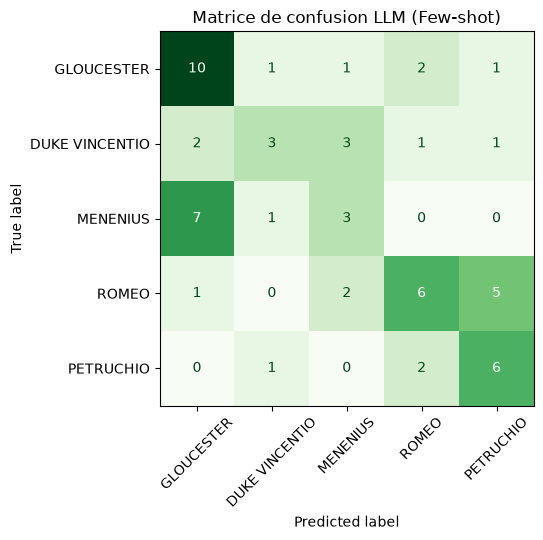

In [34]:
if resultats_zero_shot is not None:
    meilleure_llm = bilan_df.loc[bilan_df["accuracy"].idxmax(), "strategie"]
    resultat_meilleur_llm = resultats_zero_shot if meilleure_llm == "Zero-shot" else resultats_few_shot
    valides = resultat_meilleur_llm[resultat_meilleur_llm["prediction"] != "INCONNU"]

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        valides["vrai"], valides["prediction"],
        xticks_rotation=45, cmap="Greens", colorbar=False, ax=ax,
        labels=top_locuteurs,
    )
    ax.set_title(f"Matrice de confusion LLM ({meilleure_llm})")
    plt.tight_layout()
    plt.show()


### Comparaison avec tf-idf

                     modèle  accuracy
               LLM few-shot  0.466667
 Dummy (classe majoritaire)  0.261438
              LLM zero-shot  0.250000
Dummy (aléatoire stratifié)  0.196078


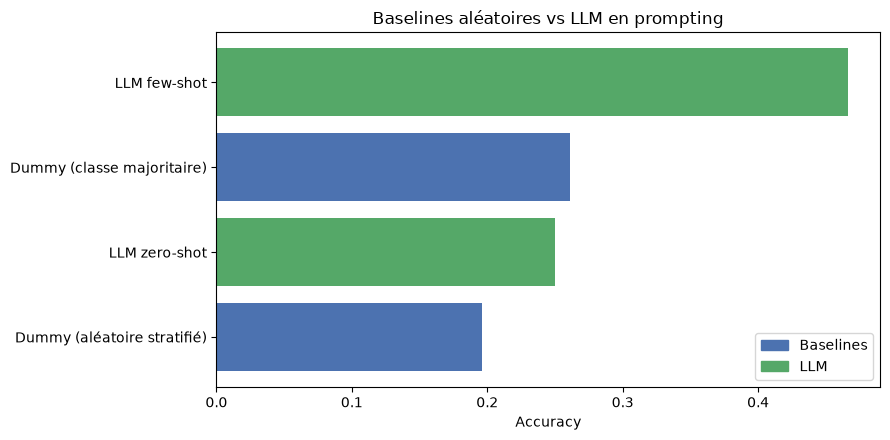

In [48]:
resultats_llm = []

if resultats_zero_shot is not None:
    resultats_llm.append({
        "modèle": "LLM zero-shot",
        "accuracy": accuracy_score(
            resultats_zero_shot["vrai"],
            resultats_zero_shot["prediction"]
        )
    })

if resultats_few_shot is not None:
    resultats_llm.append({
        "modèle": "LLM few-shot",
        "accuracy": accuracy_score(
            resultats_few_shot["vrai"],
            resultats_few_shot["prediction"]
        )
    })

llm_df = pd.DataFrame(resultats_llm)

comparaison_finale = pd.concat(
    [
        baseline_df[["modèle", "accuracy"]],
        llm_df[["modèle", "accuracy"]]
    ],
    ignore_index=True
).sort_values(
    "accuracy",
    ascending=False
)

print(comparaison_finale.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))

couleurs = [
    "#55A868" if m.startswith("LLM") else "#4C72B0"
    for m in comparaison_finale["modèle"]
]

ax.barh(
    comparaison_finale["modèle"],
    comparaison_finale["accuracy"],
    color=couleurs
)

ax.set_xlabel("Accuracy")
ax.set_title("Baselines aléatoires vs LLM en prompting")
ax.invert_yaxis()

# Légende manuelle
from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(color="#4C72B0", label="Baselines"),
    Patch(color="#55A868", label="LLM")
])

plt.tight_layout()
plt.show()